# Irrigation-constrained crop allocation in northwest Bangladesh — the whole analysis, step by step

This notebook runs the eight stages of the pipeline in order. After each stage it shows the tables and figures of the paper that the stage produces, so every exhibit appears next to the step that makes it. The last section checks every output table against `reference/` (byte-for-byte) and runs the independent check.

Run it from the repository root with the pinned environment (`requirements.txt`, Python 3.13): *Kernel → Restart & Run All*, or `jupyter execute run_all.ipynb`. A full run takes about 7 minutes; stage 6 takes most of it.

Figures are shown here as previews; the full-resolution files (PNG and TIFF at 600 dpi, and PDF) are written to `generated/figures/`.

## 0  Set-up: input check and helpers

In [1]:
import io
import os
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

ROOT = Path.cwd().resolve()
assert (ROOT / "scripts" / "run_all.py").is_file(), "Start Jupyter in the repository root"
sys.path.insert(0, str(ROOT / "scripts"))
import run_all  # stage commands, input check and reference comparison

for key in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[key] = "1"  # single-threaded linear algebra, as in run_all.py
GEN, TAB, FIG = ROOT / "generated", ROOT / "generated" / "tables", ROOT / "generated" / "figures"
pd.set_option("display.max_columns", 30, "display.width", 200, "display.precision", 3)

run_all.check_inputs()  # every input file and script against SOURCE_INPUT_MANIFEST.json
if GEN.exists():
    import shutil
    shutil.rmtree(GEN)
GEN.mkdir()
STAGES = run_all.stages()


def run_stage(number):
    """Run one pipeline stage (1-8) and print the last lines of its log."""
    name, cmd = STAGES[number - 1]
    proc = subprocess.run([str(c) for c in cmd], cwd=ROOT, text=True, capture_output=True)
    if proc.returncode:
        raise RuntimeError(proc.stderr[-2000:])
    print(f"Stage {name}: done")


def tables(*names, rows=None):
    """Build the named paper tables (stage 7, --only) and show them."""
    cmd = [str(c) for c in STAGES[6][1]] + ["--only", *names]
    subprocess.run(cmd, cwd=ROOT, check=True, capture_output=True)
    for name in names:
        for path in sorted(TAB.glob(name + "_*.csv")) + sorted(TAB.glob(name + "[ab]_*.csv")):
            display(Markdown(f"**{path.stem}**"))
            df = pd.read_csv(path)
            display(df if rows is None else df.head(rows))


def figures(*names, width=1400):
    """Draw the named paper figures (stage 8, --only) and show a preview of each."""
    cmd = [str(c) for c in STAGES[7][1]] + ["--only", *names]
    subprocess.run(cmd, cwd=ROOT, check=True, capture_output=True)
    for name in names:
        path = next(FIG.glob(name + "_*.png"))
        img = PILImage.open(path)
        img.thumbnail((width, width))
        buf = io.BytesIO()
        img.save(buf, format="PNG", optimize=True)
        display(Markdown(f"**{path.stem}**"))
        display(Image(buf.getvalue(), width=900))


def show(folder, file, rows=None):
    """Show one output file of a stage."""
    df = pd.read_csv(GEN / folder / file)
    display(Markdown(f"**{folder}/{file}**"))
    display(df if rows is None else df.head(rows))

Input and script integrity: 50 files matched


## 1  Climate predictors and crop water requirements

Seasonal climate predictors are rebuilt from the monthly NASA POWER files and checked against the yield panel. The FAO-56 crop water requirement (daily Penman–Monteith ET0, crop coefficients, effective rain, Boro percolation) is computed for four crops, 16 districts and 11 seasons, and compared with the published net irrigation requirement (NIR).

In [2]:
run_stage(1)
show("climate", "climate_check.csv")
show("climate", "crop_water_requirement_summary.csv")

Stage 1 Climate predictors and FAO-56 crop water requirements: done


**climate/climate_check.csv**

,variable,compared_with,rows,max_abs_gap,mean_abs_gap,tolerance,within_tolerance
0,season_rain_mm,analysis_panel_full.csv,528,1.240,0.114,1.500e+00,True
1,monsoon_prev_rain_mm,analysis_panel_full.csv,528,0.050,0.025,1.000e-01,True
2,season_tmean_c,analysis_panel_full.csv,528,0.005,0.002,6.000e-03,True
3,season_tmax_c,analysis_panel_full.csv,528,0.005,0.002,6.000e-03,True
4,season_tmin_c,analysis_panel_full.csv,528,0.005,0.003,6.000e-03,True
5,terminal_tmax_c,analysis_panel_full.csv,528,0.000,0.000,1.000e-09,True
6,season_rh_pct,analysis_panel_full.csv,528,0.005,0.002,6.000e-03,True
7,effective_rain_mm,nasa_pm_seasonal_cache,528,0.418,0.139,5.000e-01,True


**climate/crop_water_requirement_summary.csv**

,crop,ET0_mm,ETc_mm,effective_rain_mm,nir_fao56_mean_mm,nir_fao56_min_mm,nir_fao56_max_mm,nir_fao56_cv,published_nir_low_mm,published_nir_nominal_mm,published_nir_high_mm,retired_cache_PET_mm
0,Boro Rice,518.579,582.521,136.360,776.162,553.709,973.500,0.114,644,676.0,779,752.087
1,Maize,492.465,465.839,132.155,333.684,130.288,506.168,0.240,279,354.0,429,NaN
2,Potato,401.410,376.477,67.557,308.920,122.689,414.729,0.214,309,376.5,444,319.140
3,Wheat,357.180,309.761,63.483,246.279,68.581,336.676,0.243,227,283.0,339,488.311


## 2  Relative water scarcity index (RAWSI)

Mean of three components scaled 0–1 across districts: groundwater-trend severity, crop water demand with the published NIR, and the FAO-56 requirement. The index ranks districts; it does not enter the allocation model. Its robustness to 20 alternative constructions (Table S4, Fig. S3) is computed in stage 6.

In [3]:
run_stage(2)
show("scarcity_index", "rawsi.csv")
show("scarcity_index", "badc_depletion_check.csv")

Stage 2 Relative water scarcity index (RAWSI): done


**scarcity_index/rawsi.csv**

,rank,district,severity,demand,deficit,RAWSI
0,1,Naogaon,0.959,0.775,0.737,0.824
1,2,Joypurhat,1.000,0.543,0.571,0.705
2,3,Bogura,0.726,0.725,0.604,0.685
3,4,Gaibandha,0.216,0.944,0.792,0.651
4,5,Sirajganj,0.299,0.985,0.661,0.649
5,6,Kurigram,0.238,0.867,0.718,0.608
6,7,Dinajpur,0.358,0.709,0.696,0.588
7,8,Lalmonirhat,0.091,0.900,0.732,0.574
8,9,Chapainawabganj,0.713,0.384,0.617,0.571
9,10,Natore,0.464,0.542,0.591,0.532


**scarcity_index/badc_depletion_check.csv**

,n,spearman_rho,exact_two_sided_p
0,5,0.894,0.1


## 3  Hindcast yield models and SHAP (descriptive)

Elastic Net and gradient-boosted trees with same-season climate, tested on 2023–2025. They describe what moves yields; they are not used for planning. Fig. S2 shows the SHAP values of the boosted trees.

Stage 3 Hindcast yield models and SHAP (descriptive): done


**hindcast/07_hindcast_metrics.csv**

,crop,model,RMSE_t_ha,skill_vs_climatology,R2
0,Boro Rice,climatology,0.319,0.000,-0.836
1,Boro Rice,ElasticNet,0.227,0.287,0.068
2,Boro Rice,GBT,0.241,0.243,-0.051
3,Potato,climatology,2.982,0.000,0.357
4,Potato,ElasticNet,1.632,0.453,0.807
5,Potato,GBT,2.076,0.304,0.688
6,Wheat,climatology,0.510,0.000,-0.205
7,Wheat,ElasticNet,0.357,0.300,0.410
8,Wheat,GBT,0.403,0.210,0.247


**hindcast/08_shap_summary.csv**

,crop,climate_SHAP_share_pct,top_climate_feature
0,Boro Rice,21.691,terminal_tmax_c
1,Potato,13.057,season_tmin_c
2,Wheat,24.467,monsoon_prev_rain_mm


**FigS2_shap**

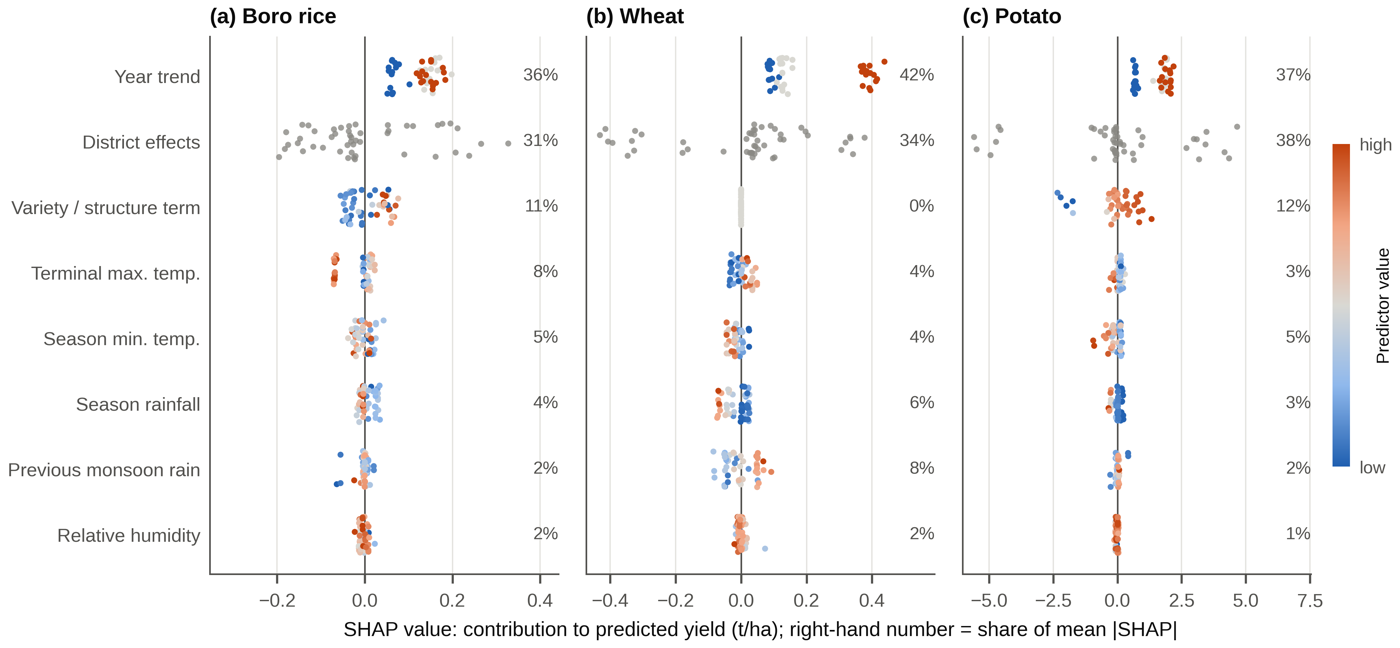

In [4]:
run_stage(3)
show("hindcast", "07_hindcast_metrics.csv")
show("hindcast", "08_shap_summary.csv")
figures("FigS2")

## 4  Decision-time yield forecasts

Forecasts for 2023–2025 made with information up to two years before the season: Elastic Net, persistence, climatology and a district trend. Table 2 gives their accuracy, Table S2 the Elastic Net settings chosen inside the training years, Table S5 what drives each Elastic Net forecast (exact contributions), and Fig. S4 the forecasts against the observed yields.

Stage 4 Decision-time yield forecasts: done


**Table2_forecast_accuracy**

,crop,model,n_forecasts,RMSE_t_ha,MAE_t_ha,skill_vs_climatology,R2
0,Boro Rice,Elastic Net,48,0.261,0.221,0.235,-0.231
1,Boro Rice,Persistence,48,0.272,0.213,0.202,-0.338
2,Boro Rice,Climatology,48,0.341,0.293,0.000,-1.103
3,Boro Rice,District trend,48,0.269,0.209,0.211,-0.310
4,Wheat,Elastic Net,48,0.432,0.356,0.210,0.138
5,Wheat,Persistence,48,0.485,0.394,0.112,-0.088
6,Wheat,Climatology,48,0.546,0.451,0.000,-0.381
7,Wheat,District trend,48,0.483,0.388,0.115,-0.082
8,Potato,Elastic Net,48,1.914,1.594,0.412,0.735
9,Potato,Persistence,48,2.163,1.717,0.336,0.662


**TableS2_decision_time_tuning**

,crop,last_training_year,inner_validation_years,inner_rmse_t_ha,alpha,l1_ratio,target_year,first_training_year
0,Boro Rice,2021,2020-2021,0.191,0.091,0.95,2023,2017
1,Wheat,2021,2020-2021,0.273,0.055,0.90,2023,2017
2,Potato,2021,2020-2021,2.009,0.248,0.95,2023,2017
3,Maize,2021,2020-2021,0.970,0.409,0.90,2023,2017
4,Boro Rice,2022,2020-2022,0.198,0.409,0.10,2024,2017
5,Wheat,2022,2020-2022,0.299,0.055,0.90,2024,2017
6,Potato,2022,2020-2022,1.820,0.248,0.95,2024,2017
7,Maize,2022,2020-2022,1.040,0.248,0.95,2024,2017
8,Boro Rice,2023,2020-2023,0.218,0.150,0.10,2025,2017
9,Wheat,2023,2020-2023,0.333,0.033,0.95,2025,2017


**TableS5_elastic_net**

,crop,target_year,last_training_year,n_training_rows,alpha,l1_ratio,intercept,coef_trend_per_sd,coef_lag2_yield_per_sd,coef_lag2_4_mean_yield_per_sd,district_effects_nonzero,district_effect_min,district_effect_max,share_of_mean_abs_contribution_pct_trend,share_of_mean_abs_contribution_pct_lag2_yield,share_of_mean_abs_contribution_pct_lag2_4_mean_yield,share_of_mean_abs_contribution_pct_district_effect
0,Boro Rice,2023,2021,80,0.091,0.95,4.099,0.000,0.000,0.061,0,0.0,0.0,0.000,0.000,100.000,0.0
1,Wheat,2023,2021,80,0.055,0.90,3.047,0.000,0.029,0.155,0,0.0,0.0,0.000,20.167,79.833,0.0
2,Potato,2023,2021,80,0.248,0.95,19.172,0.000,1.945,0.565,0,0.0,0.0,0.000,76.275,23.725,0.0
3,Maize,2023,2021,80,0.409,0.90,8.048,0.000,0.000,0.293,0,0.0,0.0,0.000,0.000,100.000,0.0
4,Boro Rice,2024,2022,96,0.409,0.10,4.116,0.002,0.044,0.048,0,0.0,0.0,7.277,47.847,44.876,0.0
5,Wheat,2024,2022,96,0.055,0.90,3.067,0.002,0.022,0.178,0,0.0,0.0,3.098,13.297,83.605,0.0
6,Potato,2024,2022,96,0.248,0.95,19.418,0.000,1.870,0.779,0,0.0,0.0,0.000,70.579,29.421,0.0
7,Maize,2024,2022,96,0.248,0.95,8.199,0.000,0.004,0.508,0,0.0,0.0,0.000,0.836,99.164,0.0
8,Boro Rice,2025,2023,112,0.150,0.10,4.144,0.048,0.060,0.071,0,0.0,0.0,46.118,28.263,25.619,0.0
9,Wheat,2025,2023,112,0.033,0.95,3.090,0.025,0.000,0.227,0,0.0,0.0,18.461,0.000,81.539,0.0


**FigS4_forecasts**

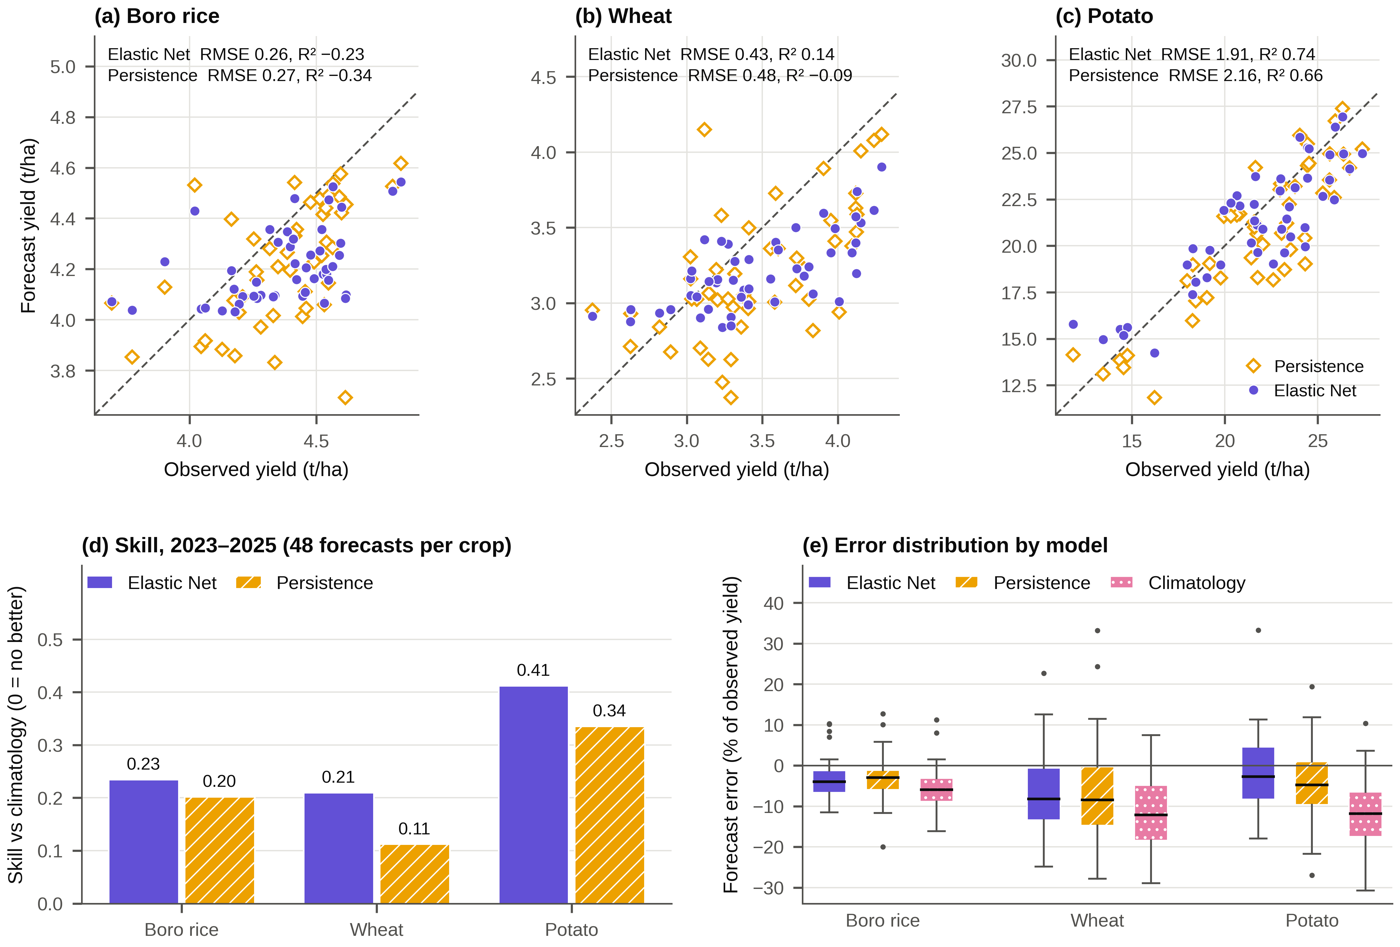

In [5]:
run_stage(4)
tables("Table2", "TableS2", "TableS5")
figures("FigS4")

## 5  Decision value of the forecasts and Γ-robust planning

Plans for 48 district-years made with each yield source are scored with the true yields (regret against the oracle). Table 4 compares the Elastic Net with each benchmark (all settings in Table S10); Table S11 gives the forecast error that would change the plan. With uncertain crop water requirements, Fig. 5 gives the budget needed to hold 80% or 90% of food energy.

Stage 5 Decision value of the forecasts and robust planning: done


**Table4_decision_value**

,budget_ratio,objective,plan,EN_vs,n_cases,loss_unit,mean_regret_EN,mean_regret_benchmark,mean_difference,bootstrap95_low,bootstrap95_high,dm_t,dm_p_two_sided,cases_EN_better,cases_benchmark_better,realised_total_difference_pct
0,0.8,food_energy,least,Persistence,48,% of oracle,1.850e-09,5.184e-09,-3.334e-09,-7.788e-09,0.000e+00,-1.589,0.133,3,0,3.957e-09
1,0.8,food_energy,least,Climatology,48,% of oracle,1.850e-09,1.850e-09,0.000e+00,0.000e+00,0.000e+00,NaN,NaN,0,0,0.000e+00
2,0.8,food_energy,least,District trend,48,% of oracle,1.850e-09,7.278e-09,-5.428e-09,-1.501e-08,0.000e+00,-1.272,0.223,5,0,4.427e-09
3,0.8,food_energy,free,Persistence,48,% of oracle,8.495e-03,3.554e-02,-2.705e-02,-7.121e-02,0.000e+00,-1.291,0.216,3,0,2.488e-02
4,0.8,food_energy,free,Climatology,48,% of oracle,8.495e-03,8.495e-03,0.000e+00,0.000e+00,0.000e+00,NaN,NaN,0,0,0.000e+00
5,0.8,food_energy,free,District trend,48,% of oracle,8.495e-03,2.735e-01,-2.650e-01,-6.940e-01,0.000e+00,-1.358,0.195,7,0,2.116e-01
6,0.8,gross_margin,least,Persistence,48,Tk per ha,3.744e-05,2.591e-05,1.152e-05,0.000e+00,3.457e-05,1.000,0.333,1,1,-5.286e-08
7,0.8,gross_margin,least,Climatology,48,Tk per ha,3.744e-05,3.957e-05,-2.138e-06,-6.415e-06,0.000e+00,-1.000,0.333,1,0,9.770e-09
8,0.8,gross_margin,least,District trend,48,Tk per ha,3.744e-05,3.496e-05,2.477e-06,-2.714e-05,3.457e-05,0.164,0.872,4,1,-2.764e-08
9,0.8,gross_margin,free,Persistence,48,Tk per ha,1.046e+02,1.520e+02,-4.739e+01,-1.846e+02,7.232e+01,-0.694,0.498,5,6,8.546e-02


**Fig5_robust_budgets**

,nir_uncertainty,uncertainty_set,gamma,feasible_cases_of_48_at_budget_0.80,feasible_cases_of_48_at_budget_0.90,feasible_cases_of_48_at_budget_1.00,budget_needed_to_hold_80pct_median,budget_needed_to_hold_80pct_worst_case,cases_holding_80pct_at_budget_0.80,budget_needed_to_hold_90pct_median,budget_needed_to_hold_90pct_worst_case,cases_holding_90pct_at_budget_0.80
0,Nominal NIR (Gamma 0),nominal,0,48,48,48,0.783,0.799,48,0.861,0.884,0
1,"Temporal NIR deviation (year-to-year CV), Gamma 1",temporal_cv,1,48,48,48,0.831,0.844,12,0.906,0.942,0
2,"Temporal NIR deviation (year-to-year CV), Gamma 2",temporal_cv,2,48,48,48,0.843,0.867,3,0.926,0.957,0
3,"Temporal NIR deviation (year-to-year CV), Gamma 3",temporal_cv,3,48,48,48,0.846,0.868,2,0.934,0.959,0
4,"Temporal NIR deviation (year-to-year CV), Gamma 4",temporal_cv,4,48,48,48,0.846,0.868,2,0.935,0.959,0
5,"Spatial upper NIR (range across districts), Ga...",spatial_upper,1,36,48,48,0.886,0.901,3,0.958,1.007,0
6,"Spatial upper NIR (range across districts), Ga...",spatial_upper,2,36,48,48,0.902,0.925,0,0.986,1.021,0
7,"Spatial upper NIR (range across districts), Ga...",spatial_upper,3,36,48,48,0.905,0.926,0,0.999,1.023,0
8,"Spatial upper NIR (range across districts), Ga...",spatial_upper,4,36,48,48,0.906,0.927,0,1.001,1.023,0


**TableS11_break_even**

,budget_ratio,plan,objective,crop,cases_plan_never_changes,median_break_even_over,median_break_even_under,median_regret_at_break_even_per_ha,median_abs_error_EN_cutoff2,cases_error_beyond_break_even_EN_cutoff2,median_abs_error_Persistence_cutoff2,cases_error_beyond_break_even_Persistence_cutoff2
0,0.8,least,food_energy,Boro Rice,48,NaN,NaN,NaN,0.052,0,0.038,0
1,0.8,least,food_energy,Wheat,48,NaN,NaN,NaN,0.095,0,0.106,0
2,0.8,least,food_energy,Potato,48,NaN,NaN,NaN,0.062,0,0.076,0
3,0.8,least,food_energy,Maize,48,NaN,NaN,NaN,0.127,0,0.084,0
4,0.8,least,gross_margin,Boro Rice,48,NaN,NaN,NaN,0.052,0,0.038,0
5,0.8,least,gross_margin,Wheat,48,NaN,NaN,NaN,0.095,0,0.106,0
6,0.8,least,gross_margin,Potato,48,NaN,NaN,NaN,0.062,0,0.076,0
7,0.8,least,gross_margin,Maize,48,NaN,NaN,NaN,0.127,0,0.084,0
8,0.8,free,food_energy,Boro Rice,18,0.620,NaN,272670.573,0.052,0,0.038,0
9,0.8,free,food_energy,Wheat,3,0.558,0.254,126261.946,0.095,7,0.106,8


**TableS10_decision_value_all**

,uncertainty_set,gamma,budget_ratio,objective,plan,EN_vs,n_cases,n_districts,loss_unit,mean_regret_EN,mean_regret_benchmark,mean_difference,bootstrap95_low,bootstrap95_high,dm_t,dm_p_two_sided,cases_EN_better,cases_benchmark_better,realised_total_difference_pct
0,nominal,0,0.8,food_energy,least,Persistence_cutoff2,48,16,% of oracle,1.850e-09,5.184e-09,-3.334e-09,-7.788e-09,0.000e+00,-1.589,0.133,3,0,3.957e-09
1,nominal,0,0.8,food_energy,least,Climatology_cutoff2,48,16,% of oracle,1.850e-09,1.850e-09,0.000e+00,0.000e+00,0.000e+00,NaN,NaN,0,0,0.000e+00
2,nominal,0,0.8,food_energy,least,Trend_cutoff2,48,16,% of oracle,1.850e-09,7.278e-09,-5.428e-09,-1.501e-08,0.000e+00,-1.272,0.223,5,0,4.427e-09
3,nominal,0,0.8,food_energy,free,Persistence_cutoff2,48,16,% of oracle,8.495e-03,3.554e-02,-2.705e-02,-7.121e-02,0.000e+00,-1.291,0.216,3,0,2.488e-02
4,nominal,0,0.8,food_energy,free,Climatology_cutoff2,48,16,% of oracle,8.495e-03,8.495e-03,0.000e+00,0.000e+00,0.000e+00,NaN,NaN,0,0,0.000e+00
5,nominal,0,0.8,food_energy,free,Trend_cutoff2,48,16,% of oracle,8.495e-03,2.735e-01,-2.650e-01,-6.940e-01,0.000e+00,-1.358,0.195,7,0,2.116e-01
6,nominal,0,0.8,gross_margin,least,Persistence_cutoff2,48,16,Tk per ha,3.744e-05,2.591e-05,1.152e-05,0.000e+00,3.457e-05,1.000,0.333,1,1,-5.286e-08
7,nominal,0,0.8,gross_margin,least,Climatology_cutoff2,48,16,Tk per ha,3.744e-05,3.957e-05,-2.138e-06,-6.415e-06,0.000e+00,-1.000,0.333,1,0,9.770e-09
8,nominal,0,0.8,gross_margin,least,Trend_cutoff2,48,16,Tk per ha,3.744e-05,3.496e-05,2.477e-06,-2.714e-05,3.457e-05,0.164,0.872,4,1,-2.764e-08
9,nominal,0,0.8,gross_margin,free,Persistence_cutoff2,48,16,Tk per ha,1.046e+02,1.520e+02,-4.739e+01,-1.846e+02,7.232e+01,-0.694,0.498,5,6,8.546e-02


**Fig5_robust_budgets**

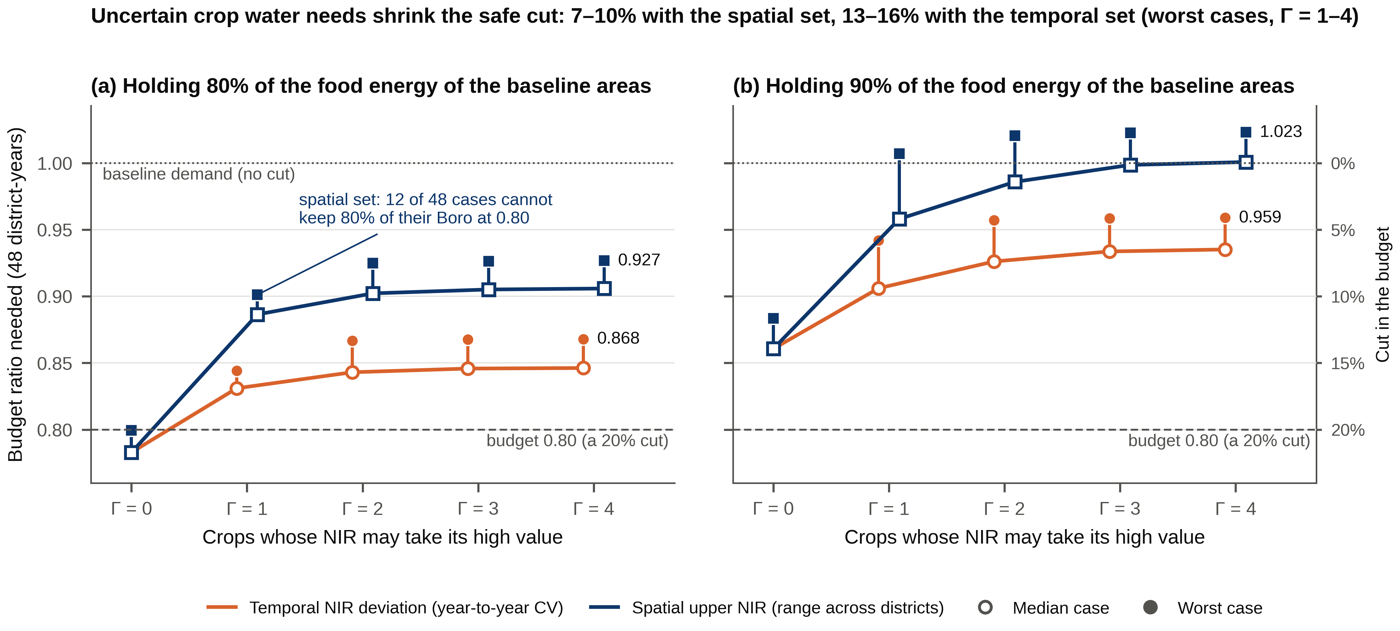

In [6]:
run_stage(5)
tables("Table4", "Fig5", "TableS11")
tables("TableS10", rows=10)
figures("Fig5")

## 6  District allocation model and its scenarios

One linear program per district: crop areas and fallow on the land pool, a water budget equal to a ratio ρ of the baseline demand, a floor on the Boro area and limits on each crop. This stage runs the model under all budgets, objectives, prices, water requirements and options, and the robustness checks of stages 2–3. It takes a few minutes.

In [7]:
run_stage(6)

Stage 6 District allocation model and scenarios: done


### 6.1  Feasibility and plans

Fig. 3: which districts can keep their Boro area under a smaller budget. Table 3 and Fig. 4: the plans of the two objectives (food energy, net return) with fallow left free or kept to its minimum. Table S6: feasibility grid and smallest fallow; Table S7: Boro floor crossed with crop limits; Table S8 and Fig. S5: the potato price; Table S9: dual values.

**Table3_plans**

,budget_ratio,plan,objective,boro_Mt,wheat_Mt,potato_Mt,maize_Mt,food_energy_trillion_kcal,gross_margin_billion_Tk,boro_pct_of_land,wheat_pct_of_land,potato_pct_of_land,maize_pct_of_land,fallow_pct_of_land,fallow_thousand_ha
0,0.8,free,food_energy,5.364,0.788,3.562,2.553,31.975,26.908,52.745,9.813,6.489,11.913,1.904e+01,4.591e+02
1,0.8,free,gross_margin,5.364,0.204,8.394,1.717,29.765,53.282,52.745,2.524,15.679,7.966,2.109e+01,5.085e+02
2,0.8,least,food_energy,5.364,0.971,3.519,2.194,31.343,24.594,52.745,12.047,6.417,10.204,1.859e+01,4.482e+02
3,0.8,least,gross_margin,5.364,0.971,3.519,2.194,31.343,24.594,52.745,12.047,6.417,10.204,1.859e+01,4.482e+02
4,0.9,free,food_energy,5.611,1.024,7.902,2.582,36.142,65.305,55.166,12.742,14.787,12.047,5.258e+00,1.268e+02
5,0.9,free,gross_margin,5.364,0.826,8.866,2.582,35.146,73.717,52.745,10.385,16.559,12.047,8.263e+00,1.993e+02
6,0.9,least,food_energy,5.611,1.027,7.902,2.575,36.128,65.258,55.166,12.790,14.787,12.009,5.248e+00,1.266e+02
7,0.9,least,gross_margin,5.611,1.027,7.902,2.575,36.128,65.258,55.166,12.790,14.787,12.009,5.248e+00,1.266e+02
8,1.0,free,food_energy,6.740,0.760,6.757,2.582,38.499,45.490,66.284,9.331,12.338,12.047,0.000e+00,0.000e+00
9,1.0,free,gross_margin,5.364,0.914,8.866,2.582,35.446,74.724,52.745,11.448,16.559,12.047,7.200e+00,1.736e+02


**TableS6a_feasibility_grid**

,water_coefficients,boro_floor,infeasible_at_budget_1.00,infeasible_at_budget_0.90,infeasible_at_budget_0.80,infeasible_at_budget_0.70
0,Fixed NIR,1.0,0,2,7,13
1,Fixed NIR,0.9,0,0,4,7
2,Fixed NIR,0.8,0,0,0,4
3,"PM climate deficit, 2023-2025 mean",1.0,0,4,10,14
4,"PM climate deficit, 2023-2025 mean",0.9,0,0,4,12
5,"PM climate deficit, 2023-2025 mean",0.8,0,0,0,6


**TableS6b_minimum_fallow**

,boro_floor,min_fallow_pct_at_budget_1.00,districts_infeasible_at_budget_1.00,min_fallow_pct_at_budget_0.90,districts_infeasible_at_budget_0.90,min_fallow_pct_at_budget_0.80,districts_infeasible_at_budget_0.80,min_fallow_pct_at_budget_0.70,districts_infeasible_at_budget_0.70
0,1.0,0.0,0,NaN,2,NaN,7,NaN,13
1,0.9,0.0,0,8.748,0,NaN,4,NaN,7
2,0.8,0.0,0,5.248,0,18.587,0,NaN,4


... (3 outputs left out)

,budget_ratio,plan,objective,unit,water_value_per_1000_m3_median,water_value_per_1000_m3_min,water_value_per_1000_m3_max,boro_floor_cost_per_ha_median,fallow_limit_value_per_ha_median,land_value_per_ha_median,fallow_pct_median,districts_water_binding,districts_boro_at_floor,districts_wheat_at_limit,districts_potato_at_limit,districts_maize_at_limit
0,0.8,free,food_energy,million kcal,3.720,2.670,8.652,10.886,0.000,0.000,1.964e+01,16,16,7,0,15
1,0.8,free,gross_margin,thousand Tk,27.398,9.574,70.156,218.548,0.000,0.000,2.063e+01,16,16,0,11,6
2,0.8,least,food_energy,million kcal,13.184,2.670,29.295,48.553,26.142,-26.142,1.888e+01,16,16,14,0,8
3,0.8,least,gross_margin,thousand Tk,374.511,74.386,818.956,1341.738,1225.502,-1225.502,1.888e+01,16,16,14,0,8
4,0.9,free,food_energy,million kcal,2.194,2.075,3.773,0.000,0.000,0.000,5.101e+00,16,5,15,11,16
5,0.9,free,gross_margin,thousand Tk,0.000,0.000,16.166,36.102,0.000,0.000,8.254e+00,5,16,11,16,16
6,0.9,least,food_energy,million kcal,2.194,2.075,25.006,0.000,0.000,0.000,5.101e+00,16,5,15,11,15
7,0.9,least,gross_margin,thousand Tk,0.000,0.000,818.956,0.000,36.102,-36.102,5.101e+00,16,5,15,11,15
8,1.0,free,food_energy,million kcal,0.887,0.000,1.619,0.000,0.000,8.524,0.000e+00,15,0,4,5,16
9,1.0,free,gross_margin,thousand Tk,0.000,0.000,0.000,34.946,0.000,0.000,7.839e+00,0,16,13,16,16


**TableS7_floor_limit_grid**

,crop_limits,boro_floor,budget_ratio,districts_infeasible,min_fallow_pct,least_fallow_plan_food_energy_pct_of_baseline,least_fallow_plan_boro_pct_of_land,food_energy_plan_free_fallow_food_energy_pct_of_baseline,gross_margin_plan_free_fallow_gross_margin_pct_of_baseline,gross_margin_plan_free_fallow_fallow_pct_of_land,least_fallow_districts_boro_at_floor,least_fallow_districts_wheat_at_limit,least_fallow_districts_potato_at_limit,least_fallow_districts_maize_at_limit
0,observed_max_2015_2025,0.0,0.8,0,12.710,87.814,45.767,87.814,241.083,58.477,0.0,16.0,16.0,16.0
1,observed_max_2015_2025,0.0,0.9,0,4.900,95.171,54.723,95.171,241.083,58.477,0.0,15.0,13.0,16.0
2,observed_max_2015_2025,0.5,0.8,0,12.999,87.626,46.132,87.626,184.535,26.381,2.0,16.0,14.0,16.0
3,observed_max_2015_2025,0.5,0.9,0,4.900,95.171,54.723,95.171,185.932,25.720,0.0,15.0,13.0,16.0
4,observed_max_2015_2025,0.6,0.8,0,13.312,87.425,46.525,87.425,171.628,20.727,2.0,16.0,14.0,16.0
5,observed_max_2015_2025,0.6,0.9,0,4.900,95.171,54.723,95.171,174.426,19.383,0.0,15.0,13.0,16.0
6,observed_max_2015_2025,0.7,0.8,0,14.311,86.602,47.691,86.774,155.852,16.903,7.0,15.0,9.0,13.0
7,observed_max_2015_2025,0.7,0.9,0,4.949,95.143,54.783,95.143,162.274,13.374,1.0,15.0,13.0,16.0
8,observed_max_2015_2025,0.8,0.8,0,18.587,82.324,52.745,83.983,107.399,21.086,16.0,14.0,0.0,8.0
9,observed_max_2015_2025,0.8,0.9,0,5.248,94.892,55.166,94.928,148.589,8.263,5.0,15.0,11.0,15.0


**Fig3_feasibility**

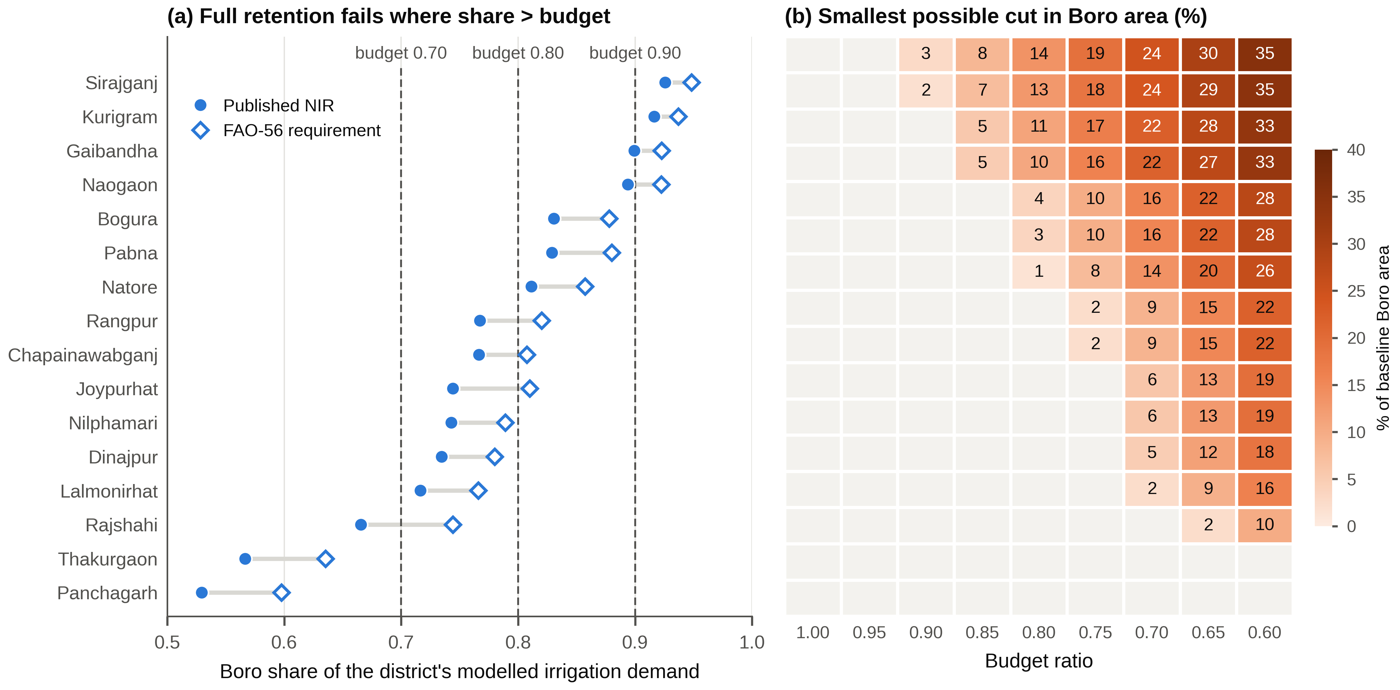

**Fig4_plans**

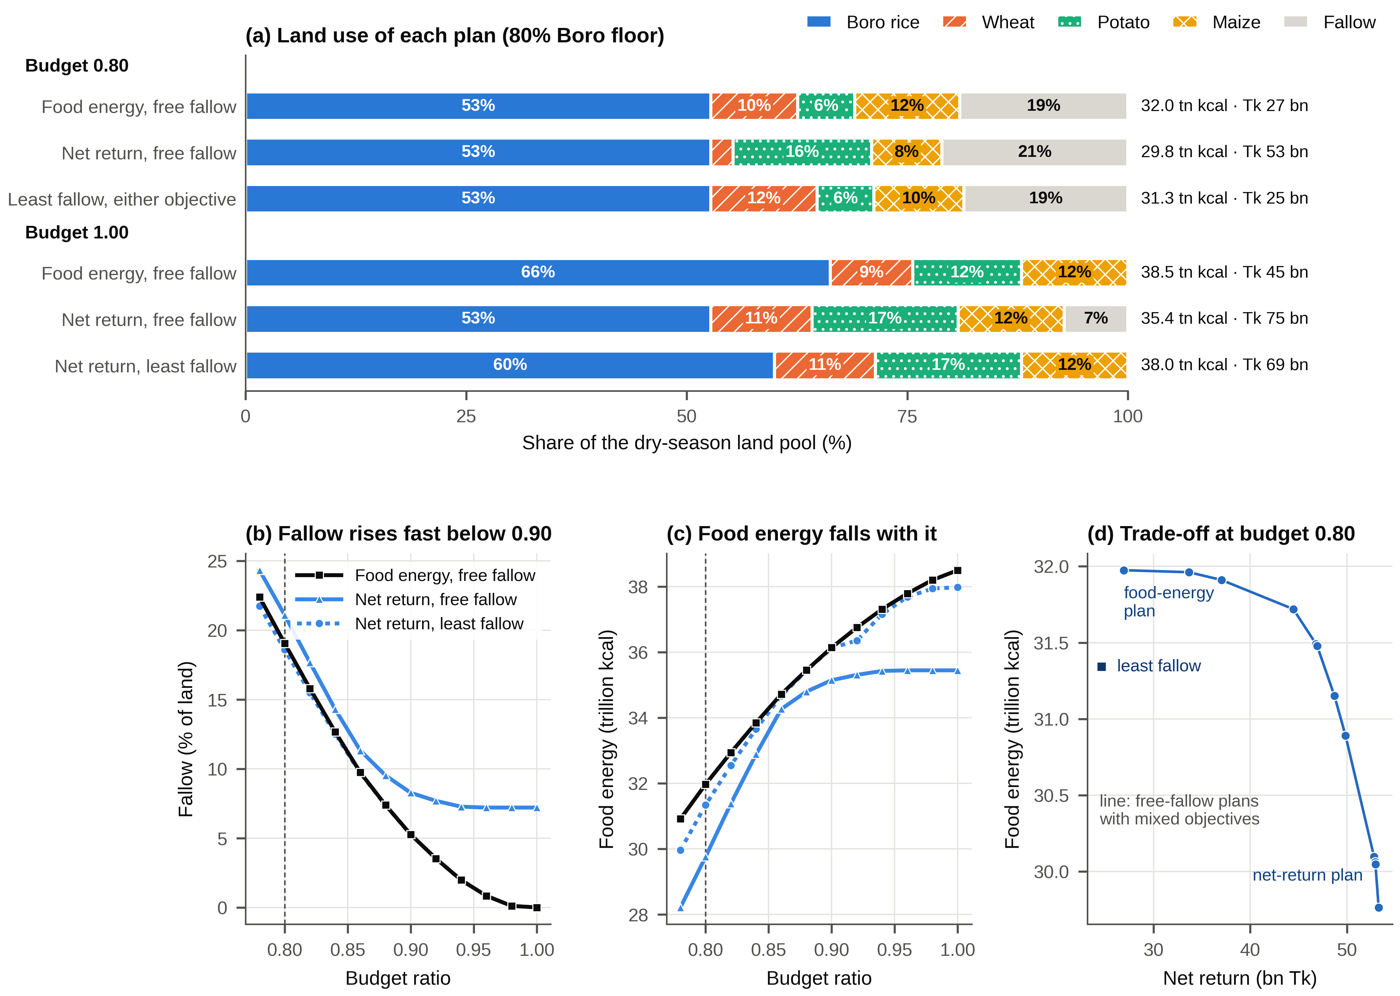

**FigS5_potato_price**

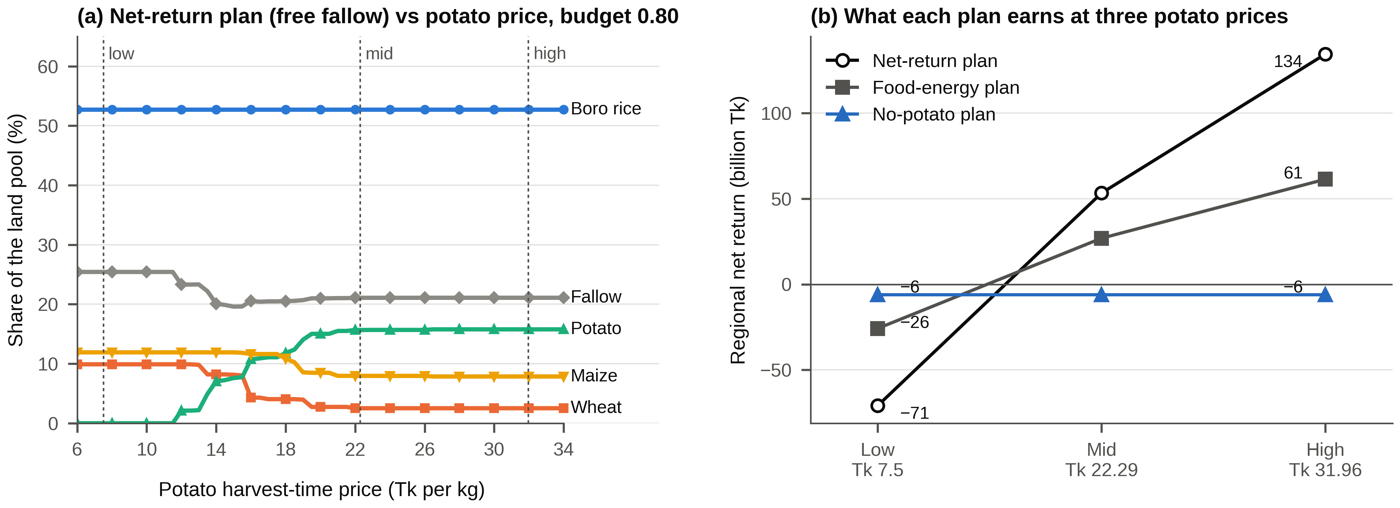

In [8]:
tables("Table3", "TableS6", "TableS8", "TableS9")
tables("TableS7", rows=14)
figures("Fig3", "Fig4", "FigS5")

### 6.2  Checks of the yield models and of RAWSI

Table S3: hindcast models with spatial hold-out and fixed effects. Table S4 and Fig. S3: RAWSI with its rank range over 20 alternative constructions. Fig. S1: the crop data.

**TableS3_hindcast_models**

,crop,climatology_RMSE_t_ha,elastic_net_RMSE_t_ha,elastic_net_skill_vs_climatology,elastic_net_R2,gbt_RMSE_t_ha,gbt_skill_vs_climatology,gbt_R2,gbt_R2_leave_one_district_out,gbt_R2_leave_one_climate_cell_out,fixed_effects_within_R2
0,Boro Rice,0.319,0.227,0.287,0.068,0.241,0.243,-0.051,-0.034,0.074,0.081
1,Wheat,0.510,0.357,0.300,0.410,0.403,0.210,0.247,0.155,0.166,0.034
2,Potato,2.982,1.632,0.453,0.807,2.076,0.304,0.688,0.107,0.101,0.170


**TableS4_rawsi**

,rank,district,groundwater_component,demand_component,deficit_component,RAWSI,best_rank_20_variants,worst_rank_20_variants,share_of_variants_in_top5,boro_water_share
0,1,Naogaon,0.959,0.775,0.737,0.824,1,5,1.00,0.894
1,2,Joypurhat,1.000,0.543,0.571,0.705,2,11,0.85,0.744
2,3,Bogura,0.726,0.725,0.604,0.685,3,8,0.95,0.831
3,4,Gaibandha,0.216,0.944,0.792,0.651,1,8,0.90,0.899
4,5,Sirajganj,0.299,0.985,0.661,0.649,2,9,0.90,0.926
5,6,Kurigram,0.238,0.867,0.718,0.608,4,10,0.15,0.916
6,7,Dinajpur,0.358,0.709,0.696,0.588,6,9,0.00,0.735
7,8,Lalmonirhat,0.091,0.900,0.732,0.574,3,11,0.05,0.716
8,9,Chapainawabganj,0.713,0.384,0.617,0.571,4,12,0.10,0.767
9,10,Natore,0.464,0.542,0.591,0.532,6,10,0.00,0.811


**FigS1_crop_data**

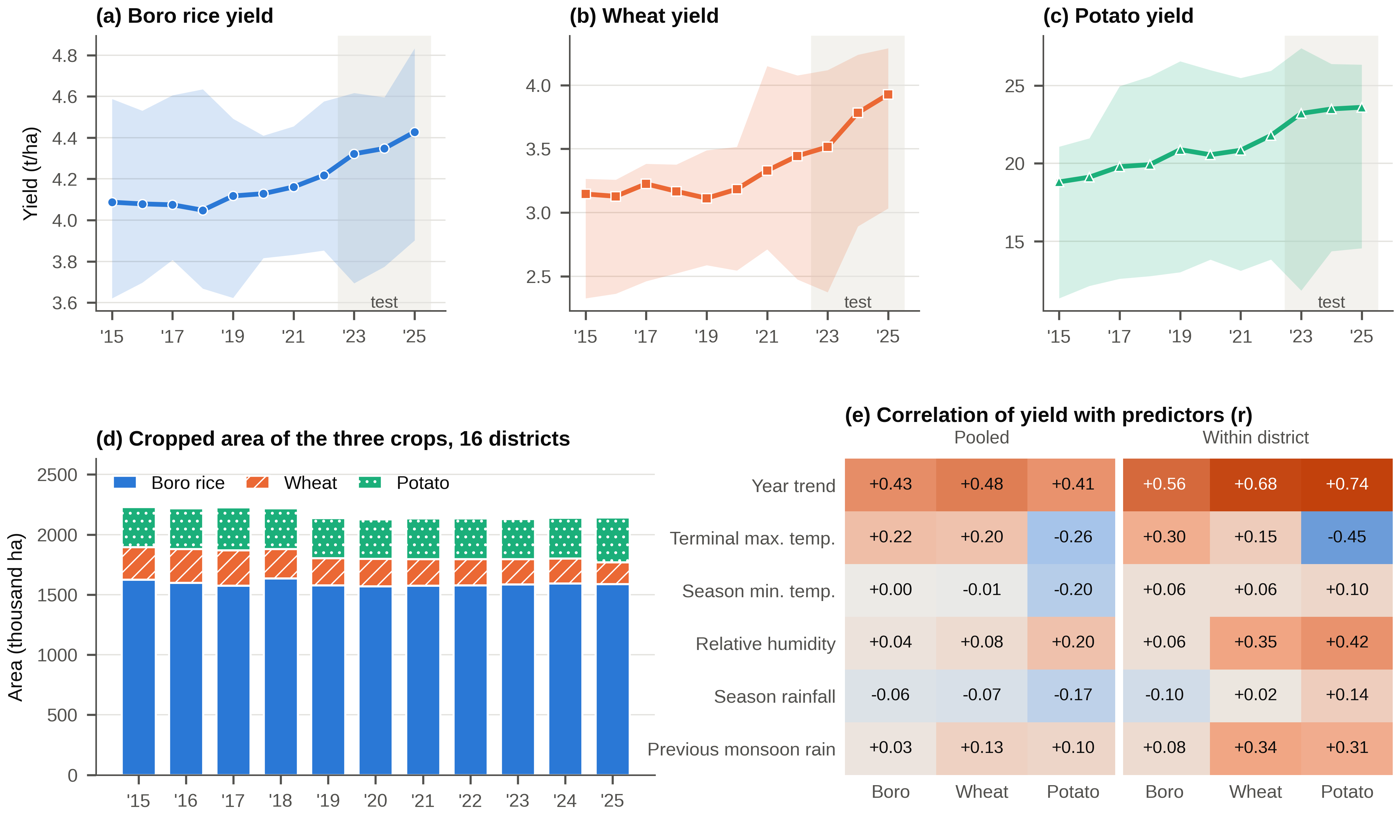

**FigS3_rawsi**

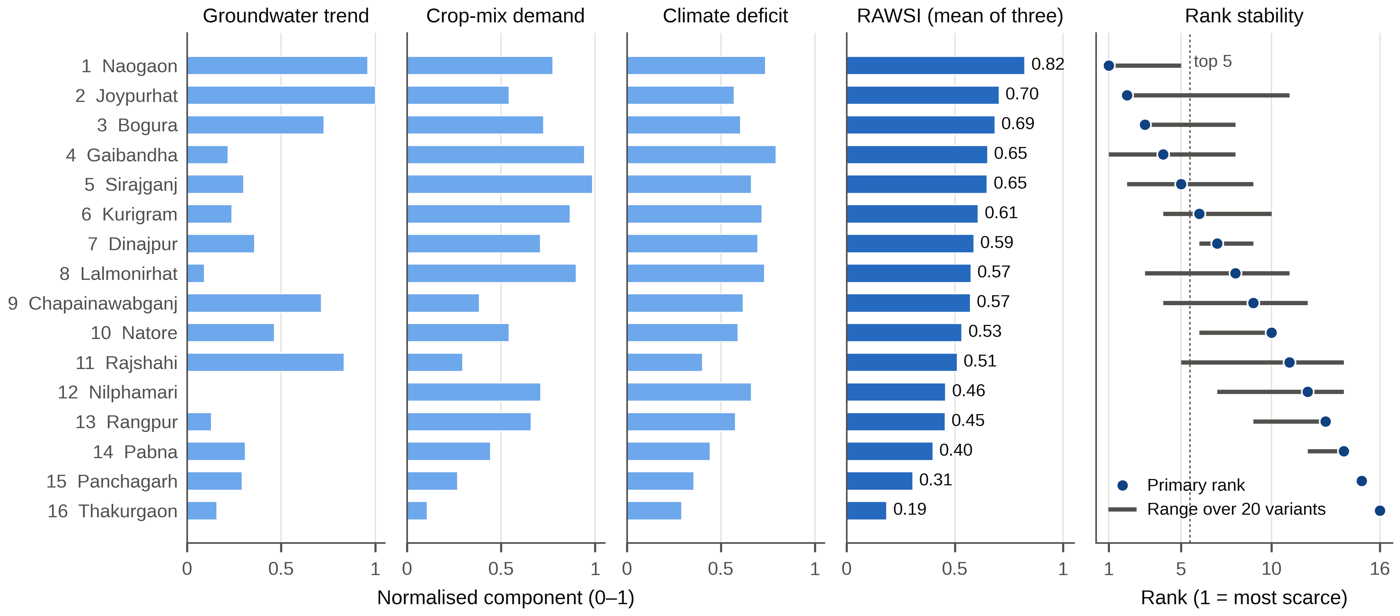

In [9]:
tables("TableS3", "TableS4")
figures("FigS1", "FigS3")

### 6.3  Alternate wetting and drying and low-water crops

Table S12 and Fig. 6: AWD on part of the Boro area, and the model value of water next to what farmers pay (Table S14). Table S13: AWD saving crossed with a yield loss. Table S15 and Fig. 7: lentil and mustard in a six-crop variant.

**TableS13_awd_yield_grid**

,water_saving,adoption_share,boro_yield_effect_on_awd_area_pct,boro_yield_change_pct,budget_ratio,min_fallow_pct,least_fallow_food_energy_food_energy_pct_of_baseline,least_fallow_food_energy_gross_margin_pct_of_baseline,free_gross_margin_food_energy_pct_of_baseline,free_gross_margin_gross_margin_pct_of_baseline
0,0.15,0.5,0.0,0.00,0.8,11.502,89.151,100.473,87.517,136.445
1,0.15,0.5,-2.5,-1.25,0.8,11.502,88.540,94.688,86.909,130.692
2,0.15,0.5,-5.4,-2.70,0.8,11.502,87.831,87.977,86.204,124.019
3,0.15,0.5,-10.0,-5.00,0.8,11.502,86.707,77.332,85.086,113.434
4,0.15,1.0,0.0,0.00,0.8,5.611,94.650,122.389,91.508,146.616
5,0.15,1.0,-2.5,-2.50,0.8,5.611,93.368,110.250,90.293,135.110
6,0.15,1.0,-5.4,-5.40,0.8,5.611,91.881,96.168,88.884,121.763
7,0.15,1.0,-10.0,-10.00,0.8,5.611,89.522,73.832,86.648,100.592
8,0.20,0.5,0.0,0.00,0.8,9.409,91.098,112.404,89.779,142.622
9,0.20,0.5,-2.5,-1.25,0.8,9.409,90.480,106.560,89.171,136.869


**TableS14_water_value_vs_charges**

,budget_ratio,plan,districts_water_binding,water_value_Tk_per_m3_min,water_value_Tk_per_m3_median,water_value_Tk_per_m3_max,districts_above_highest_charge,bmda_dtw_hourly_charge_Tk_per_m3_low,bmda_dtw_hourly_charge_Tk_per_m3_high,median_value_over_bmda_dtw_hourly_charge_high,boro_irrigation_cost_per_ha_2015_16_Tk_per_m3_low,boro_irrigation_cost_per_ha_2015_16_Tk_per_m3_high,median_value_over_boro_irrigation_cost_per_ha_2015_16_high,boro_irrigation_cost_per_ha_2016_17_Tk_per_m3_low,boro_irrigation_cost_per_ha_2016_17_Tk_per_m3_high,median_value_over_boro_irrigation_cost_per_ha_2016_17_high
0,0.8,free,16,9.574,27.398,70.156,16,0.57,0.979,27.983,1.756,3.078,8.900,0.834,5.419,5.056
1,0.8,least,16,74.386,374.511,818.956,16,0.57,0.979,382.496,1.756,3.078,121.658,0.834,5.419,69.108
2,0.9,free,5,0.000,0.000,16.166,5,0.57,0.979,0.000,1.756,3.078,0.000,0.834,5.419,0.000
3,0.9,least,16,0.000,0.000,818.956,5,0.57,0.979,0.000,1.756,3.078,0.000,0.834,5.419,0.000
4,1.0,free,0,0.000,0.000,0.000,0,0.57,0.979,0.000,1.756,3.078,0.000,0.834,5.419,0.000
5,1.0,least,0,0.000,0.000,0.000,0,0.57,0.979,0.000,1.756,3.078,0.000,0.834,5.419,0.000


**TableS12_awd_scenarios**

,water_saving,adoption_share,yield_effect,boro_yield_change_pct,objective,min_fallow_pct,food_energy_trillion_kcal,food_energy_trillion_kcal_change_vs_conventional,gross_margin_billion_Tk,gross_margin_billion_Tk_change_vs_conventional,boro_pct_of_land,wheat_pct_of_land,potato_pct_of_land,maize_pct_of_land
0,0.00,1.0,none,0.0,food_energy,18.587,31.343,0.000,24.594,0.000,52.745,12.047,6.417,10.204
1,0.00,1.0,none,0.0,gross_margin,18.587,31.343,0.000,24.594,0.000,52.745,12.047,6.417,10.204
2,0.15,0.5,none,0.0,food_energy,11.502,33.942,2.599,49.846,25.252,53.041,12.454,11.517,11.486
3,0.15,0.5,none,0.0,gross_margin,11.502,33.942,2.599,49.846,25.252,53.041,12.454,11.517,11.486
4,0.15,0.5,carrijo_2017_all_awd,-2.7,food_energy,11.502,33.440,2.097,43.646,19.052,53.041,12.454,11.517,11.486
5,0.15,0.5,carrijo_2017_all_awd,-2.7,gross_margin,11.502,33.440,2.097,43.646,19.052,53.041,12.454,11.517,11.486
6,0.15,1.0,none,0.0,food_energy,5.611,36.036,4.693,60.719,36.124,55.636,12.786,13.970,11.996
7,0.15,1.0,none,0.0,gross_margin,5.611,36.036,4.693,60.719,36.124,55.636,12.786,13.970,11.996
8,0.15,1.0,carrijo_2017_all_awd,-5.4,food_energy,5.611,34.982,3.639,47.710,23.116,55.636,12.786,13.970,11.996
9,0.15,1.0,carrijo_2017_all_awd,-5.4,gross_margin,5.611,34.982,3.639,47.710,23.116,55.636,12.786,13.970,11.996


**TableS15_low_water_crops**

,budget_ratio,awd,low_water_crop_limit_x_baseline,objective,min_fallow_thousand_ha,min_fallow_pct_of_pool,four_crop_model_min_fallow_thousand_ha,lentil_x_baseline,mustard_x_baseline,boro_thousand_ha,wheat_thousand_ha,potato_thousand_ha,maize_thousand_ha,lentil_thousand_ha,mustard_thousand_ha,food_energy_pct_of_baseline,gross_margin_pct_of_baseline
0,0.8,none,1.0,food_energy,440.635,16.328,448.206,1.490,1.097,1271.923,279.943,139.502,236.912,55.140,274.615,81.772,58.556
1,0.8,none,1.0,gross_margin,440.635,16.328,448.206,1.490,1.097,1271.923,279.943,139.502,236.912,55.140,274.615,81.772,58.556
2,0.8,none,1.5,food_energy,365.418,13.541,448.206,1.606,1.502,1271.923,270.794,131.279,223.981,59.443,375.833,81.347,61.724
3,0.8,none,1.5,gross_margin,365.418,13.541,448.206,1.606,1.502,1271.923,270.794,131.279,223.981,59.443,375.833,81.347,61.724
4,0.8,none,2.0,food_energy,278.902,10.335,448.206,1.911,1.974,1271.923,239.885,120.275,223.085,70.734,493.866,81.429,67.123
5,0.8,none,2.0,gross_margin,278.902,10.335,448.206,1.911,1.974,1271.923,239.885,120.275,223.085,70.734,493.866,81.429,67.123
6,0.8,none,3.0,food_energy,203.405,7.537,448.206,1.099,2.476,1271.923,217.866,111.516,233.759,40.683,619.519,82.504,73.276
7,0.8,none,3.0,gross_margin,203.405,7.537,448.206,2.253,2.441,1271.923,164.824,138.912,225.521,83.376,610.710,81.580,83.142
8,0.8,none,4.0,food_energy,158.488,5.873,448.206,1.356,2.700,1271.923,211.117,101.445,229.805,50.177,675.715,82.402,75.077
9,0.8,none,4.0,gross_margin,158.488,5.873,448.206,2.113,2.711,1271.923,155.242,149.827,206.705,78.209,678.277,80.982,88.960


**Fig6_awd_water_value**

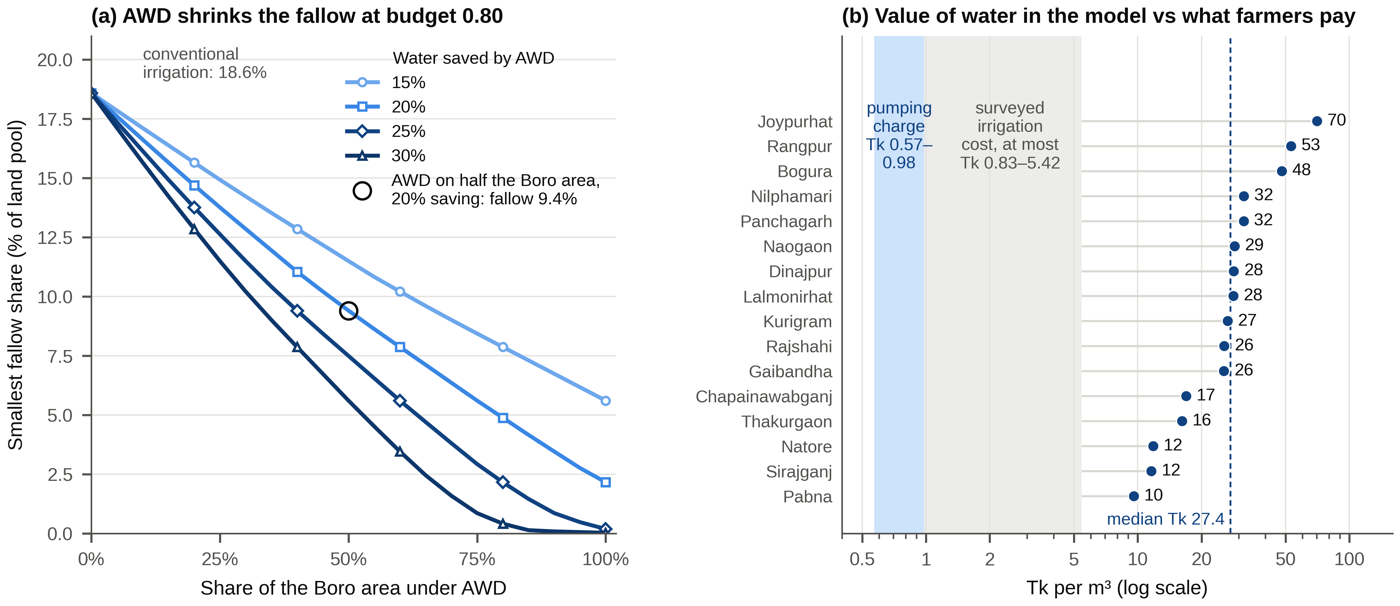

**Fig7_low_water_crops**

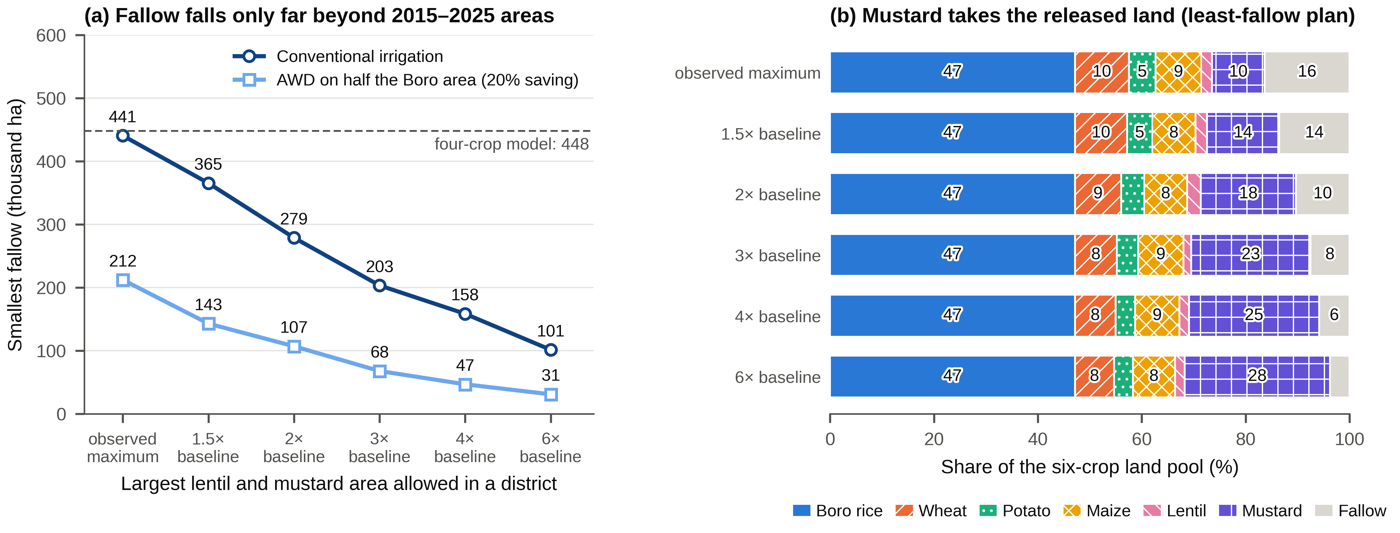

In [10]:
tables("TableS13", "TableS14")
tables("TableS12", "TableS15", rows=12)
figures("Fig6", "Fig7")

### 6.4  Sensitivity

Fig. 8 and Table S16: one input at a time at budget 0.80. Table S17: Boro and wheat at the procurement price. Table S18: maize price and cost.

**TableS16_sensitivity**

,group,factor,settings,outcome,change_unit,main_value,low_value,high_value,low_change,high_change,swing
0,input,"Water coefficients: FAO-56, single years 2015-...",11,min_fallow_pct,percentage points,18.587,17.132,18.900,-1.455,0.313,1.768
1,input,"Water coefficients: FAO-56, single years 2015-...",11,food_energy_trillion_kcal,% of main,31.975,31.642,32.020,-1.040,0.140,1.180
2,input,"Water coefficients: FAO-56, single years 2015-...",11,gross_margin_billion_Tk,% of main,53.282,53.026,55.002,-0.480,3.228,3.708
3,input,"Yields: persistence, climatology, observed, hi...",4,min_fallow_pct,percentage points,18.587,18.587,18.587,0.000,0.000,0.000
4,input,"Yields: persistence, climatology, observed, hi...",4,food_energy_trillion_kcal,% of main,31.975,30.617,34.277,-4.246,7.201,11.446
5,input,"Yields: persistence, climatology, observed, hi...",4,gross_margin_billion_Tk,% of main,53.282,27.776,78.740,-47.870,47.779,95.649
6,input,Crop limits: 1.5 x baseline area,1,min_fallow_pct,percentage points,18.587,18.702,18.702,0.115,0.115,0.115
7,input,Crop limits: 1.5 x baseline area,1,food_energy_trillion_kcal,% of main,31.975,33.781,33.781,5.648,5.648,5.648
8,input,Crop limits: 1.5 x baseline area,1,gross_margin_billion_Tk,% of main,53.282,58.230,58.230,9.286,9.286,9.286
9,input,Boro floor: 0.75 / 0.85 of baseline,2,min_fallow_pct,percentage points,18.587,15.938,21.704,-2.648,3.117,5.766


**TableS17_procurement_price**

,budget_ratio,plan,boro_wheat_price,boro_price_Tk_per_kg_paddy,wheat_price_Tk_per_kg,boro_margin_Tk_per_ha,wheat_margin_Tk_per_ha,gross_margin_billion_Tk,boro_pct_of_land,wheat_pct_of_land,potato_pct_of_land,maize_pct_of_land,fallow_pct_of_land
0,0.8,free,harvest_time_market,27.67,36.983,-34343.521,32029.521,53.282,52.745,2.524,15.679,7.966,2.109e+01
1,0.8,free,procurement,36.00,36.000,19634.126,28874.790,121.819,52.745,2.524,15.679,7.966,2.109e+01
2,0.8,least,harvest_time_market,27.67,36.983,-34343.521,32029.521,24.594,52.745,12.047,6.417,10.204,1.859e+01
3,0.8,least,procurement,36.00,36.000,19634.126,28874.790,92.377,52.745,12.047,6.417,10.204,1.859e+01
4,1.0,free,harvest_time_market,27.67,36.983,-34343.521,32029.521,74.724,52.745,11.448,16.559,12.047,7.200e+00
5,1.0,free,procurement,36.00,36.000,19634.126,28874.790,146.127,60.105,11.288,16.559,12.047,0.000e+00
6,1.0,least,harvest_time_market,27.67,36.983,-34343.521,32029.521,68.871,59.945,11.448,16.559,12.047,5.391e-10
7,1.0,least,procurement,36.00,36.000,19634.126,28874.790,146.127,60.105,11.288,16.559,12.047,0.000e+00


**TableS18_maize_price_cost**

,budget_ratio,plan,maize_price_scenario,maize_price_Tk_per_kg,maize_cost_scenario,maize_cost_Tk_per_kg,maize_margin_Tk_per_ha,maize_area_thousand_ha,gross_margin_billion_Tk,food_energy_trillion_kcal,fallow_pct_of_land
0,0.8,free,low,18.65,minus_20pct,9.6,79021.383,191.928,49.843,29.762,21.086
1,0.8,free,low,18.65,reported,12.0,58065.436,152.820,45.912,29.211,20.679
2,0.8,free,low,18.65,plus_20pct,14.4,37109.489,125.124,42.836,28.749,20.423
3,0.8,free,mid,23.00,minus_20pct,9.6,117004.036,192.096,57.308,29.765,21.086
4,0.8,free,mid,23.00,reported,12.0,96048.089,192.096,53.282,29.765,21.086
5,0.8,free,mid,23.00,plus_20pct,14.4,75092.143,191.928,49.259,29.762,21.086
6,0.8,free,high,28.50,minus_20pct,9.6,165028.081,213.216,67.344,30.204,21.033
7,0.8,free,high,28.50,reported,12.0,144072.134,204.554,63.044,30.040,21.055
8,0.8,free,high,28.50,plus_20pct,14.4,123116.187,204.554,58.757,30.040,21.055
9,0.8,least,low,18.65,minus_20pct,9.6,79021.383,246.060,20.207,31.343,18.587


**Fig8_sensitivity**

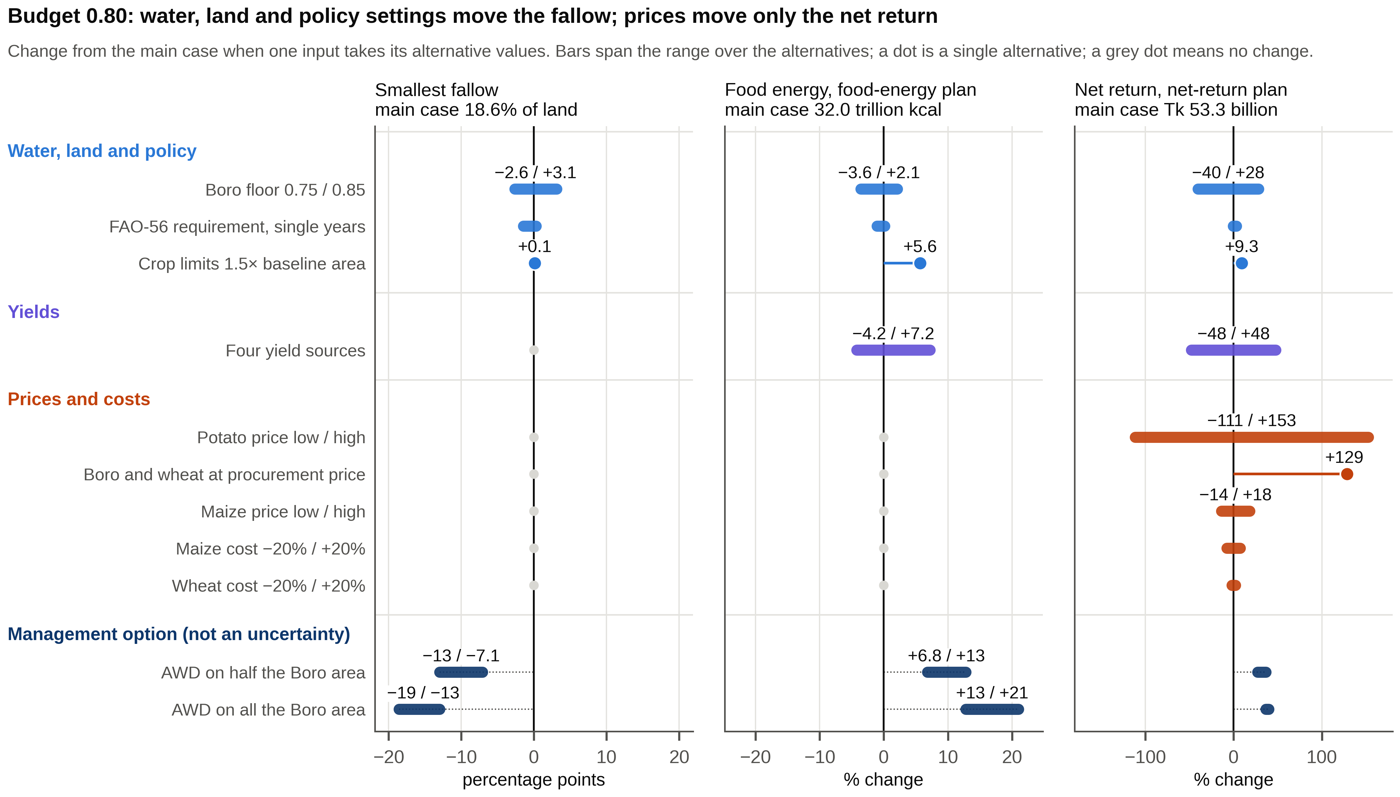

In [11]:
tables("TableS16", "TableS17")
tables("TableS18", rows=12)
figures("Fig8")

### 6.5  Land accounting and simple allocation rules

Table S19: the largest irrigated area with no land balance at all. Table S20: two simple rules (proportional cut; Boro first to its floor) against the optimised plans.

In [12]:
tables("TableS19", "TableS20")

**TableS19_land_accounting_check**

,budget_ratio,boro_floor,crop_limits,land_pool_thousand_ha,irrigated_area_with_land_balance_thousand_ha,irrigated_area_without_land_balance_thousand_ha,reduction_with_land_balance_thousand_ha,reduction_without_land_balance_thousand_ha,districts_where_land_balance_binds
0,0.8,0.8,observed_max_2015_2025,2411.436,1963.230,1963.230,448.206,448.206,0
1,0.9,0.8,observed_max_2015_2025,2411.436,2284.875,2284.875,126.560,126.560,0


**TableS20_rule_baselines**

,budget_ratio,plan,irrigated_area_thousand_ha,reduction_pct_of_pool,reduction_thousand_ha,boro_pct_of_pool,wheat_pct_of_pool,potato_pct_of_pool,maize_pct_of_pool,food_energy_pct_of_baseline,net_return_pct_of_baseline
0,0.8,proportional_cut,1929.149,20.000,482.287,52.745,6.629,11.557,9.068,80.000,80.000
1,0.8,boro_first,1929.149,20.000,482.287,52.745,6.629,11.557,9.068,80.000,80.000
2,0.8,optimised_least_fallow_food_energy,1963.230,18.587,448.206,52.745,12.047,6.417,10.204,82.324,49.574
3,0.8,optimised_free_fallow_food_energy,1952.312,19.039,459.123,52.745,9.813,6.489,11.913,83.983,54.238
4,0.8,optimised_free_fallow_net_return,1902.972,21.086,508.463,52.745,2.524,15.679,7.966,78.180,107.399
5,0.9,proportional_cut,2170.292,10.000,241.144,59.339,7.458,13.002,10.202,90.000,90.000
6,0.9,boro_first,2210.364,8.338,201.072,57.594,8.287,14.446,11.335,92.324,113.898
7,0.9,optimised_least_fallow_food_energy,2284.875,5.248,126.560,55.166,12.790,14.787,12.009,94.892,131.539
8,0.9,optimised_free_fallow_food_energy,2284.646,5.258,126.790,55.166,12.742,14.787,12.047,94.928,131.633
9,0.9,optimised_free_fallow_net_return,2212.169,8.263,199.266,52.745,10.385,16.559,12.047,92.312,148.589


### 6.6  Study area, framework and decision-value maps

Fig. 1 (study area), Fig. 2 (stages of the analysis, with small charts drawn from the outputs above) and Fig. S6 (decision value and maps of dual values) combine results of several stages.

**Fig1_study_area**

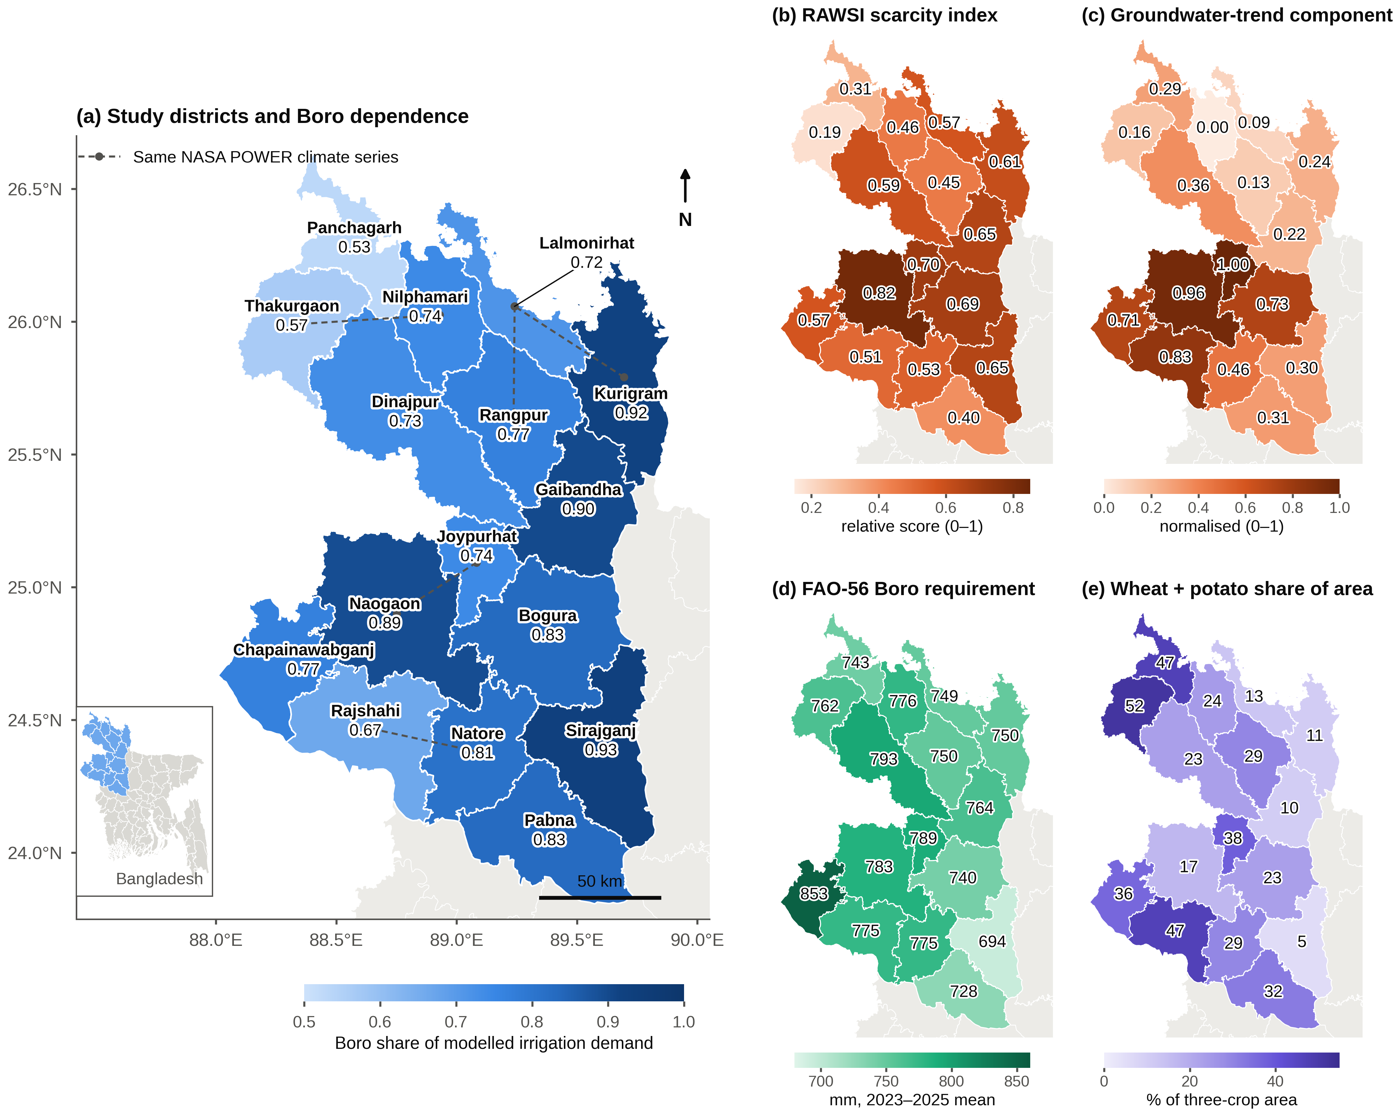

**Fig2_framework**

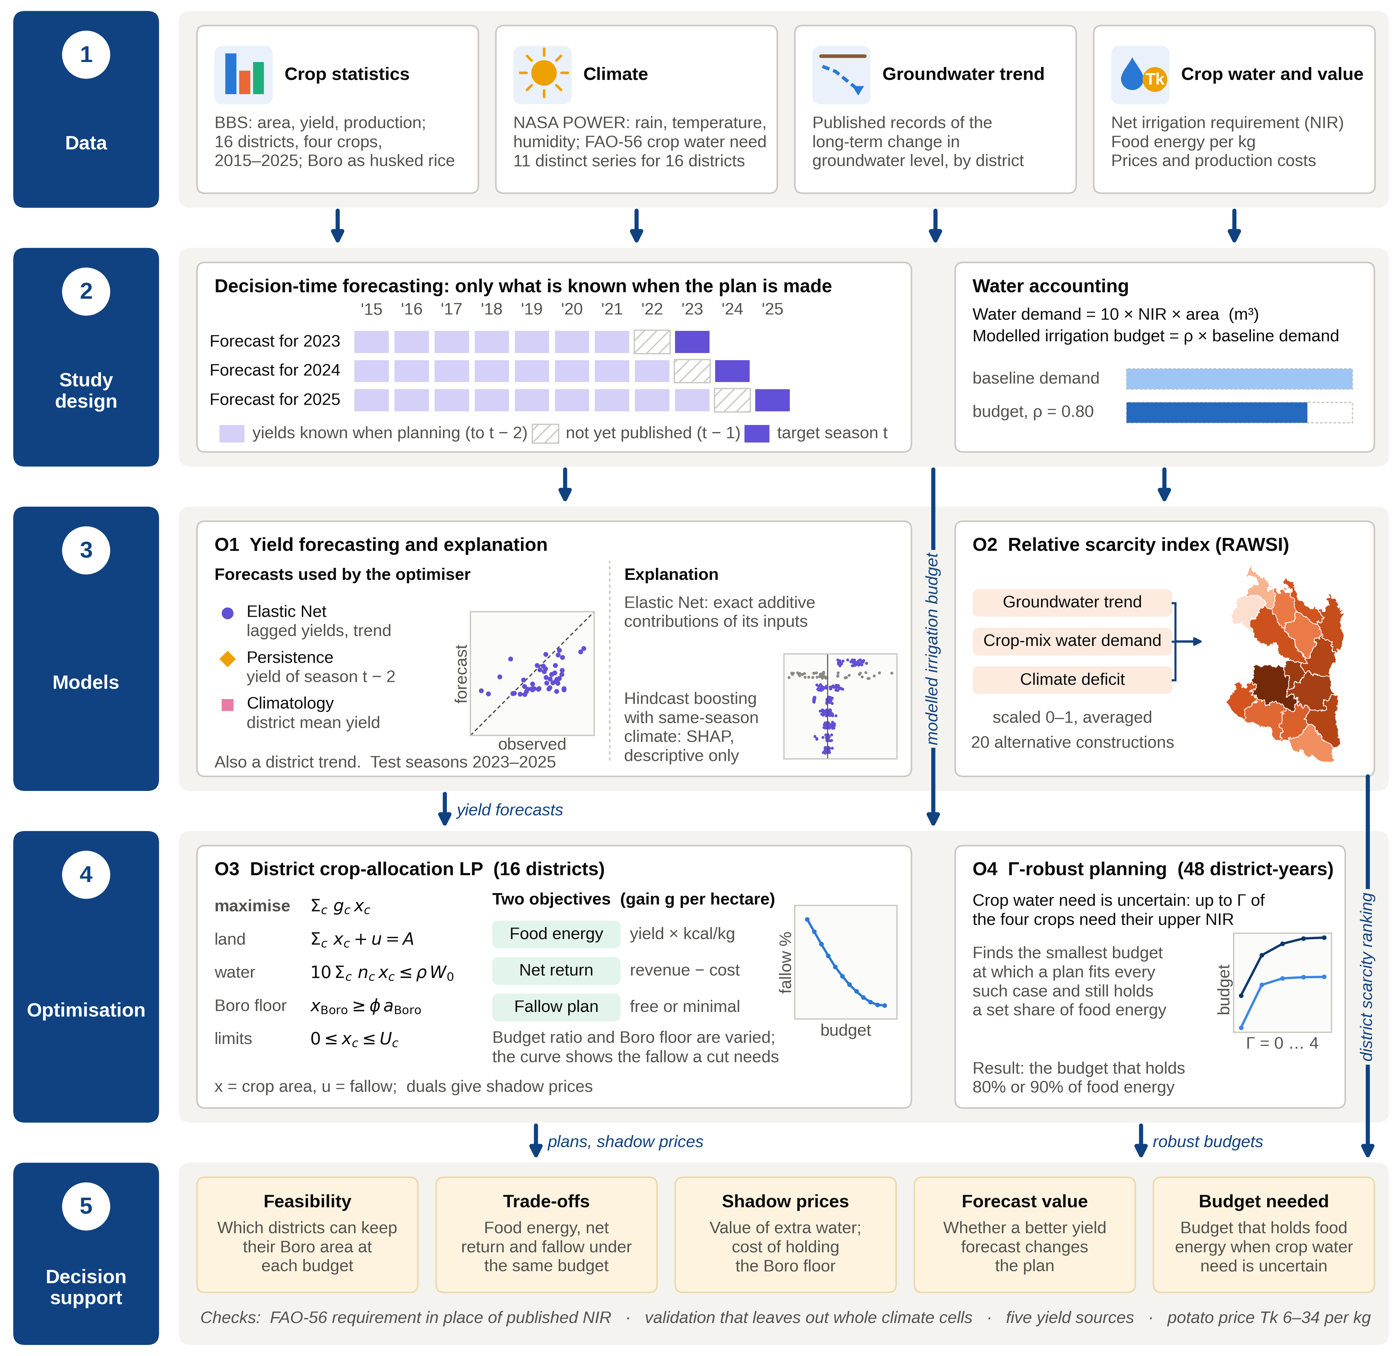

**FigS6_decision_value_dual_values**

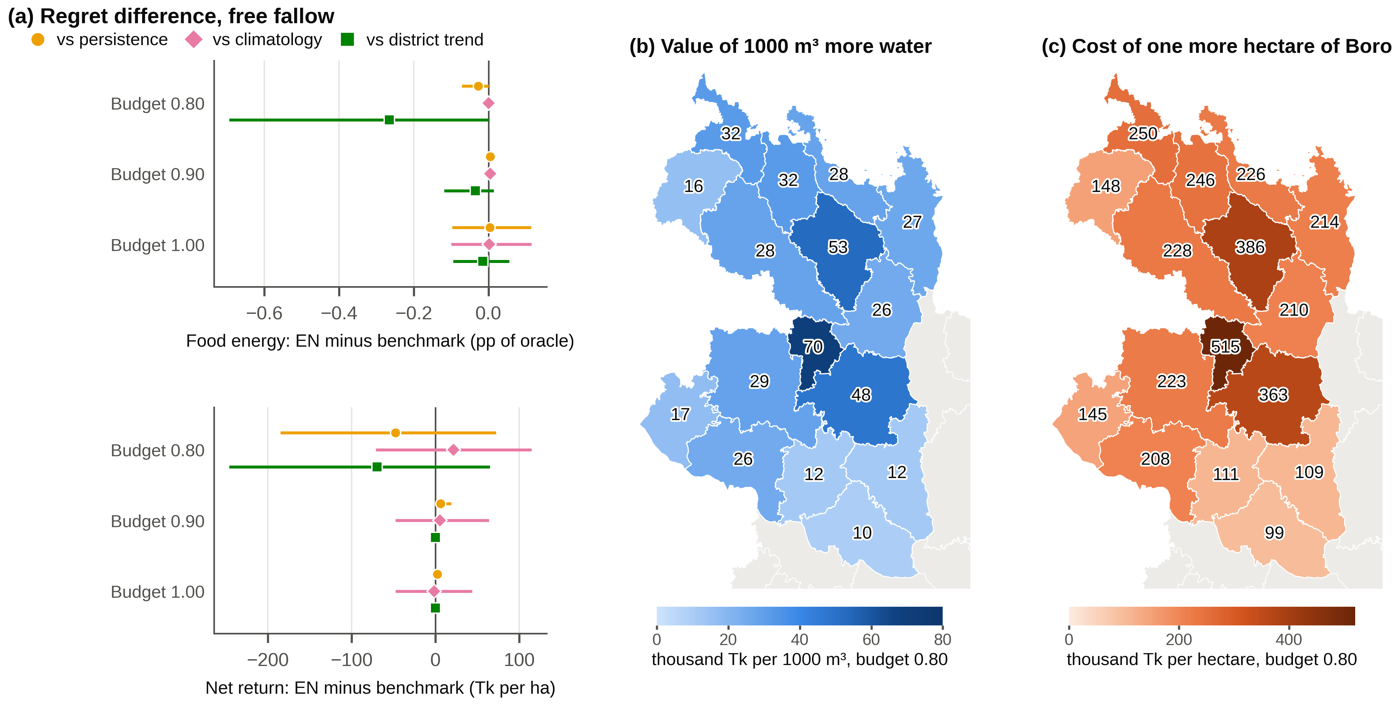

In [13]:
figures("Fig1", "Fig2", "FigS6")

## 7  Check every output against `reference/`

All tables are built once more in one run (this also writes `generated/tables/TABLES.md`), then every output CSV is compared byte-for-byte with its copy in `reference/`. Finally the independent check re-computes the main results by different routes.

In [14]:
run_stage(7)
rows = run_all.compare_with_reference()
print("SUCCESS", len(rows), "exact CSV matches with reference/")
check = subprocess.run([sys.executable, "checks/independent_check.py", "."], cwd=ROOT, text=True, capture_output=True)
lines = check.stdout.strip().splitlines()
print(sum(l.startswith("PASS") for l in lines), "checks passed;", lines[-1])

Stage 7 Tables: done


SUCCESS 91 exact CSV matches with reference/


44 checks passed; ALL PASS
